# 03 — Listing-Type Demand and Pricing Gap
**Course:** BAN5600

Two analyses that support RQ3 and the business recommendations:

1. **Demand by listing type:** the listing-type half of RQ3 (notebook 01 covers neighborhoods).
2. **Pricing gap:** how far each listing's price sits from a "fair price" estimated from comparable listings.

Fair prices are **out-of-fold**: each listing is predicted by a random forest trained on the other four
folds. In-sample predictions would be misleading because the forest nearly memorizes its training data
(train R² 0.95, test R² 0.85).

## 1. Setup

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from pyspark.ml.regression import RandomForestRegressor
from pyspark.sql import Window, functions as F

CODE_DIR = Path.cwd() if Path.cwd().name == "code" else Path.cwd() / "code"
sys.path.insert(0, str(CODE_DIR))
import airbnb_prep as prep
import plot_style as ps

PROJECT_DIR = CODE_DIR.parent
FIG_DIR, OUT_DIR = PROJECT_DIR / "figures", PROJECT_DIR / "outputs"
SEED, FOLDS = 42, 5
RF_PARAMS = dict(numTrees=200, maxDepth=15)  # best values from notebook 02

spark = prep.get_spark("Airbnb-NYC-Demand-Gap")
ps.apply()
listings = prep.load_listings(spark, str(PROJECT_DIR / "listings.csv"))
priced = prep.add_model_features(listings.filter(F.col("price").isNotNull())).cache()
sample, _ = prep.analytic_sample(listings)
data = prep.add_model_features(sample).cache()
print(f"Priced listings: {priced.count():,}; analytic sample: {data.count():,}")

Priced listings: 19,406; analytic sample: 19,018


## 2. Demand by listing type
Population: all priced listings, as in notebook 01. **Reviews are not comparable across stay types**:
monthly guests rarely review, so room types are compared within each stay type.

In [2]:
def demand_profile(group_cols, min_listings=50):
    t = (priced.groupBy(*group_cols)
         .agg(F.count("*").alias("listings"),
              F.mean("availability_365").alias("mean_availability_365"),
              F.mean("number_of_reviews_ltm").alias("mean_reviews_ltm"),
              F.mean((F.col("number_of_reviews_ltm") > 0).cast("double")).alias("share_reviewed_12mo"),
              F.mean("estimated_occupancy_l365d").alias("mean_est_occupied_nights"),
              F.percentile_approx("price", 0.5, 10000).alias("median_price"))
         .filter(F.col("listings") >= min_listings)
         .orderBy(*group_cols).toPandas())
    t.to_csv(OUT_DIR / f"demand_by_{'_'.join(group_cols)}.csv", index=False)
    return t

demand_stay = demand_profile(["stay_type"])
demand_room_stay = demand_profile(["stay_type", "room_type"])
demand_property = demand_profile(["stay_type", "property_grp"])
display(demand_stay.round(2), demand_room_stay.round(2))
demand_property.sort_values(["stay_type", "mean_est_occupied_nights"], ascending=[True, False]).round(2)

,stay_type,listings,mean_availability_365,mean_reviews_ltm,share_reviewed_12mo,mean_est_occupied_nights,median_price
0,30+ nights,14260,261.08,0.82,0.36,45.13,146.64
1,Under 30 nights,5146,232.53,24.84,0.81,153.68,377.00


,stay_type,room_type,listings,mean_availability_365,mean_reviews_ltm,share_reviewed_12mo,mean_est_occupied_nights,median_price
0,30+ nights,Entire home/apt,8683,260.13,0.93,0.40,51.30,197.87
1,30+ nights,Private room,5441,261.75,0.67,0.29,35.92,77.00
2,30+ nights,Shared room,115,284.63,0.38,0.23,22.57,49.93
3,Under 30 nights,Entire home/apt,1428,214.94,27.66,0.93,195.29,435.00
4,Under 30 nights,Hotel room,408,297.90,1.70,0.29,17.61,649.94
5,Under 30 nights,Private room,3270,232.14,26.54,0.82,152.03,309.00


,stay_type,property_grp,listings,mean_availability_365,mean_reviews_ltm,share_reviewed_12mo,mean_est_occupied_nights,median_price
1,30+ nights,Entire guest suite,131,242.25,1.48,0.51,70.76,118.19
0,30+ nights,Entire condo,524,247.16,1.04,0.39,56.90,253.17
3,30+ nights,Entire loft,185,249.25,1.40,0.41,55.68,279.59
4,30+ nights,Entire rental unit,6633,260.02,0.94,0.42,53.21,192.92
5,30+ nights,Entire townhouse,226,236.68,0.98,0.38,50.63,255.82
10,30+ nights,Private room in townhouse,332,168.08,0.86,0.41,49.32,67.44
8,30+ nights,Private room in home,1322,264.20,0.71,0.33,40.34,69.45
9,30+ nights,Private room in rental unit,3343,270.10,0.66,0.27,34.11,78.35
2,30+ nights,Entire home,736,272.09,0.59,0.30,33.66,183.56
7,30+ nights,Private room in condo,158,242.32,0.51,0.28,30.72,95.50


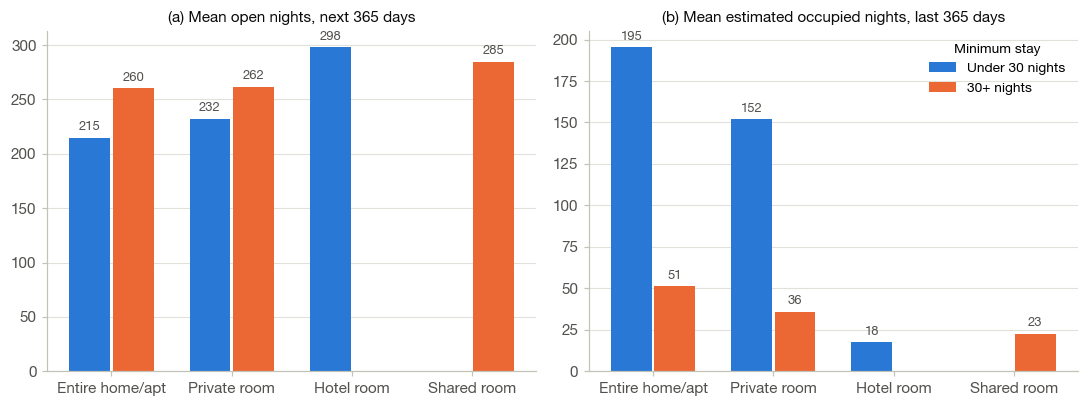

In [3]:
order = [r for r in ["Entire home/apt", "Private room", "Hotel room", "Shared room"] if r in set(demand_room_stay.room_type)]
stays = ["Under 30 nights", "30+ nights"]
fig, axes = plt.subplots(1, 2, figsize=(10, 3.8))
for ax, col, title in [(axes[0], "mean_availability_365", "(a) Mean open nights, next 365 days"),
                       (axes[1], "mean_est_occupied_nights", "(b) Mean estimated occupied nights, last 365 days")]:
    p = demand_room_stay.pivot(index="room_type", columns="stay_type", values=col).reindex(order)
    x = np.arange(len(order))
    for i, s in enumerate(stays):
        vals = p[s].values
        bars = ax.bar(x + (i - 0.5) * 0.36, np.nan_to_num(vals), width=0.34, color=ps.SERIES[i], label=s)
        ax.bar_label(bars, labels=["" if np.isnan(v) else f"{v:.0f}" for v in vals], padding=3, fontsize=8.5, color=ps.INK2)
    ax.set_xticks(x, order)
    ax.set_title(title, fontsize=10)
    ax.grid(axis="x", visible=False)
axes[1].legend(title="Minimum stay", title_fontsize=9, loc="upper right")
fig.tight_layout()
ps.save(fig, FIG_DIR, "figD1_demand_by_listing_type")

## 3. Fair price (out-of-fold random forest)
Two versions, both excluding demand signals (availability and review counts) so that fair price
describes the listing, not how well it has been selling:

* **Model A, comparables:** all listing attributes including location. Gap = listing price vs. comparable listings.
* **Model B, attributes only:** model A without any location feature. It prices a listing as if it were
  located at an average place in the city, so `fair_A / fair_B - 1` estimates the **location premium**.

Folds come from a hash of the listing id, so they are reproducible.

In [4]:
DEMAND_SIGNALS = {"availability_30", "availability_365", "log_reviews", "log_reviews_ltm"}
LOCATION_NUM = {"latitude", "longitude", "km_to_midtown"}
num_a = [c for c in prep.NUM_FEATURES if c not in DEMAND_SIGNALS]
num_b = [c for c in num_a if c not in LOCATION_NUM]
cat_a = prep.CAT_FEATURES
cat_b = [c for c in cat_a if c != "neighbourhood_grp"]

frame = data.withColumn("fold", F.pmod(F.xxhash64("id", F.lit(SEED)), F.lit(FOLDS)))
for c in set(num_a):
    frame = frame.withColumn(c, F.col(c).cast("double"))
frame = frame.cache()

def out_of_fold(cat, num, name):
    parts = []
    for k in range(FOLDS):
        rf = RandomForestRegressor(featuresCol="features", labelCol="log_price", seed=SEED,
                                   featureSubsetStrategy="onethird", **RF_PARAMS)
        model = prep.model_pipeline(rf, cat, num).fit(frame.filter(F.col("fold") != k))
        parts.append(model.transform(frame.filter(F.col("fold") == k)).select("id", "prediction").toPandas())
        print(name, "fold", k, "done")
    p = pd.concat(parts).rename(columns={"prediction": f"log_fair_{name}"})
    p["id"] = p["id"].astype(str)
    return p

oof = out_of_fold(cat_a, num_a, "a").merge(out_of_fold(cat_b, num_b, "b"), on="id", validate="one_to_one")
assert len(oof) == frame.count()

a fold 0 done


a fold 1 done


a fold 2 done


a fold 3 done


a fold 4 done


b fold 0 done


b fold 1 done


b fold 2 done


b fold 3 done


b fold 4 done


In [5]:
scored = frame.join(spark.createDataFrame(oof), "id")
fit_rows = []
for name in ["a", "b"]:
    log_col = f"log_fair_{name}"
    # exp(log prediction) estimates the typical (median) price. No smearing correction here: that targets
    # the mean, which is pulled up by expensive listings and would make most listings look under-priced.
    scored = scored.withColumn(f"fair_{name}", F.exp(log_col))
    r = scored.select(
        (1 - F.sum((F.col("log_price") - F.col(log_col)) ** 2)
         / F.sum((F.col("log_price") - F.lit(scored.select(F.mean("log_price")).first()[0])) ** 2)).alias("r2"),
        F.sqrt(F.mean((F.col("log_price") - F.col(log_col)) ** 2)).alias("rmse"),
        F.percentile_approx(F.abs(F.col("price") / F.col(f"fair_{name}") - 1), 0.5, 10000).alias("mdape")).first()
    fit_rows.append({"model": name, "oof_r2_log": r.r2, "oof_rmse_log": r.rmse, "median_abs_pct_error": r.mdape})

scored = (scored
          .withColumn("gap_pct", F.col("price") / F.col("fair_a") - 1)
          .withColumn("location_premium", F.col("fair_a") / F.col("fair_b") - 1)
          .withColumn("gap_group", F.when(F.col("gap_pct") < -0.2, "More than 20% below")
                      .when(F.col("gap_pct") > 0.2, "More than 20% above").otherwise("Within 20%"))
          .cache())
fit = pd.DataFrame(fit_rows)
fit.to_csv(OUT_DIR / "fair_price_fit.csv", index=False)
fit.round(3)

,model,oof_r2_log,oof_rmse_log,median_abs_pct_error
0,a,0.822,0.342,0.174
1,b,0.780,0.380,0.201


## 4. How are listings priced relative to comparables?
Differences within ±20% are close to the model's typical error, so only larger gaps are flagged.

In [6]:
n = scored.count()
gap_summary = (scored.groupBy("stay_type", "gap_group").count()
               .withColumn("share_of_stay_type", F.col("count") / F.sum("count").over(Window.partitionBy("stay_type")))
               .orderBy("stay_type", "gap_group").toPandas())
gap_summary.to_csv(OUT_DIR / "pricing_gap_summary.csv", index=False)
print(scored.groupBy("gap_group").count().withColumn("share", F.round(F.col("count") / n, 3)).toPandas())
gap_summary.round(3)

             gap_group  count  share
0  More than 20% below   4212  0.221
1  More than 20% above   4247  0.223
2           Within 20%  10559  0.555


,stay_type,gap_group,count,share_of_stay_type
0,30+ nights,More than 20% above,3013,0.216
1,30+ nights,More than 20% below,3172,0.227
2,30+ nights,Within 20%,7788,0.557
3,Under 30 nights,More than 20% above,1234,0.245
4,Under 30 nights,More than 20% below,1040,0.206
5,Under 30 nights,Within 20%,2771,0.549


## 5. Do listings priced below comparables sell better?
Listings are sorted into gap quintiles within each stay type (Q1 = cheapest relative to fair price).
This is an association, not a causal effect: a listing may also be cheap because of something the data
cannot see, and a popular listing may simply not have raised its price.

In [7]:
q = scored.withColumn("gap_quintile", F.ntile(5).over(Window.partitionBy("stay_type").orderBy("gap_pct")))
gap_demand = (q.groupBy("stay_type", "gap_quintile")
              .agg(F.count("*").alias("listings"),
                   F.percentile_approx("gap_pct", 0.5, 10000).alias("median_gap"),
                   F.mean("availability_365").alias("mean_availability_365"),
                   F.mean((F.col("number_of_reviews_ltm") > 0).cast("double")).alias("share_reviewed_12mo"),
                   F.mean("number_of_reviews_ltm").alias("mean_reviews_ltm"),
                   F.mean("estimated_occupancy_l365d").alias("mean_est_occupied_nights"),
                   F.mean(F.col("estimated_occupancy_l365d") * F.col("price")).alias("mean_est_revenue_365"))
              .orderBy("stay_type", "gap_quintile").toPandas())
gap_demand.to_csv(OUT_DIR / "gap_quintile_demand.csv", index=False)
gap_demand.round(3)

,stay_type,gap_quintile,listings,median_gap,mean_availability_365,share_reviewed_12mo,mean_reviews_ltm,mean_est_occupied_nights,mean_est_revenue_365
0,30+ nights,1,2795,-0.313,236.973,0.425,1.017,56.592,6497.448
1,30+ nights,2,2795,-0.147,251.325,0.438,0.982,56.266,7303.593
2,30+ nights,3,2795,-0.036,263.308,0.396,0.881,50.522,7356.076
3,30+ nights,4,2794,0.102,272.466,0.355,0.815,42.925,7820.110
4,30+ nights,5,2794,0.509,283.538,0.177,0.439,20.082,6642.248
5,Under 30 nights,1,1009,-0.295,212.349,0.854,32.764,169.144,39647.415
6,Under 30 nights,2,1009,-0.135,227.255,0.837,26.659,163.294,48176.212
7,Under 30 nights,3,1009,-0.015,233.947,0.824,24.896,163.642,55030.701
8,Under 30 nights,4,1009,0.138,235.507,0.814,22.426,153.096,66518.770
9,Under 30 nights,5,1009,0.462,251.518,0.779,19.682,131.852,86313.641


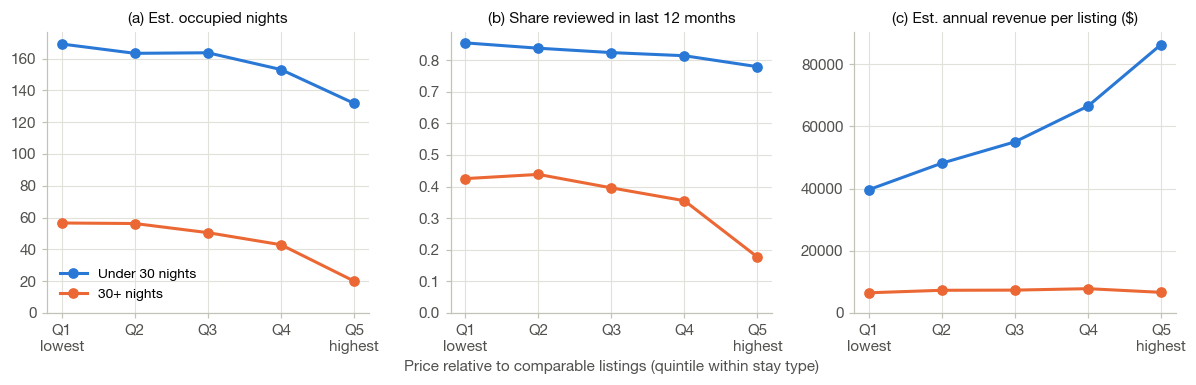

In [8]:
fig, axes = plt.subplots(1, 3, figsize=(11, 3.6))
for ax, col, title in [(axes[0], "mean_est_occupied_nights", "(a) Est. occupied nights"),
                       (axes[1], "share_reviewed_12mo", "(b) Share reviewed in last 12 months"),
                       (axes[2], "mean_est_revenue_365", "(c) Est. annual revenue per listing ($)")]:
    for i, s in enumerate(stays):
        d = gap_demand[gap_demand.stay_type == s]
        ax.plot(d.gap_quintile, d[col], color=ps.SERIES[i], lw=2, marker="o", ms=6, label=s)
    ax.set_xticks([1, 2, 3, 4, 5], ["Q1\nlowest", "Q2", "Q3", "Q4", "Q5\nhighest"])
    ax.set_title(title, fontsize=10)
    ax.set_ylim(bottom=0)
axes[1].set_xlabel("Price relative to comparable listings (quintile within stay type)")
axes[0].legend()
fig.tight_layout()
ps.save(fig, FIG_DIR, "figD2_gap_vs_demand")

## 6. Neighborhoods: location premium and demand
Model A knows the neighborhood, so its gap measures pricing *within* a neighborhood and cannot show a
whole neighborhood being under-priced. The location premium is used instead. A neighborhood with high
demand and a low premium is a **candidate** for under-pricing: guests are active there although the
market pays little for the location. It is a lead to check, not proof.

The demand index comes from notebook 01 (`outputs/neighbourhood_demand.csv`). The top-host share flags
neighborhoods dominated by one operator.

In [9]:
hood_gap = (scored.groupBy("neighbourhood")
            .agg(F.count("*").alias("sample_listings"),
                 F.percentile_approx("location_premium", 0.5, 10000).alias("median_location_premium"),
                 F.percentile_approx("gap_pct", 0.5, 10000).alias("median_gap_within"),
                 F.mean((F.col("gap_pct") < -0.2).cast("double")).alias("share_20pct_below"))
            .toPandas())
demand = pd.read_csv(OUT_DIR / "neighbourhood_demand.csv")
hoods = demand.merge(hood_gap, on="neighbourhood", validate="one_to_one")
hoods.to_csv(OUT_DIR / "neighbourhood_pricing_gap.csv", index=False)
cols = ["neighbourhood", "borough", "listings", "demand_index", "median_price", "median_location_premium", "share_20pct_below", "top_host_share"]
high = hoods[hoods.demand_index >= hoods.demand_index.quantile(0.75)]
# -5% keeps only premiums clearly below zero, not small differences within model noise
candidates = high[(high.median_location_premium < -0.05) & (high.top_host_share < 0.5)].sort_values("median_location_premium")
print(f"{len(hoods)} neighborhoods; {len(high)} in top demand quartile; {len(candidates)} candidates")
print("corr(demand index, location premium) =", round(hoods.demand_index.corr(hoods.median_location_premium), 3))
candidates[cols].round(3)

72 neighborhoods; 18 in top demand quartile; 4 candidates
corr(demand index, location premium) = 0.107


,neighbourhood,borough,listings,demand_index,median_price,median_location_premium,share_20pct_below,top_host_share
13,Richmond Hill,Queens,77,0.581,100.80,-0.096,0.182,0.091
11,Inwood,Manhattan,65,0.640,61.12,-0.092,0.131,0.169
3,Woodhaven,Queens,60,0.824,86.66,-0.080,0.298,0.133
6,Elmhurst,Queens,125,0.746,72.68,-0.071,0.189,0.216


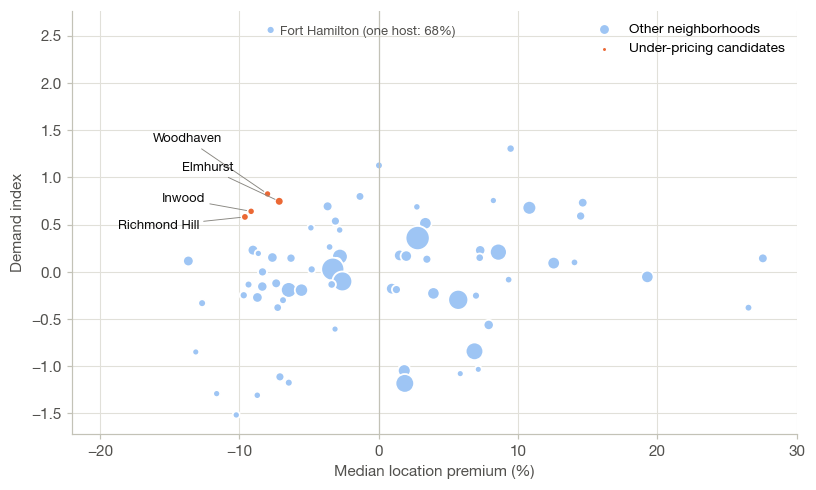

In [10]:
fig, ax = plt.subplots(figsize=(8.5, 5))
rest = hoods[~hoods.neighbourhood.isin(candidates.neighbourhood)]
size = lambda n: 12 + n / hoods.listings.max() * 240
ax.scatter(rest.median_location_premium * 100, rest.demand_index, s=size(rest.listings), color=ps.LIGHT_BLUE,
           edgecolors="white", linewidths=1.2, label="Other neighborhoods")
ax.scatter(candidates.median_location_premium * 100, candidates.demand_index, s=size(candidates.listings), color=ps.SERIES[1],
           edgecolors="white", linewidths=1.2, label="Under-pricing candidates")
# stacked to the left with leader lines, because the candidates sit close together
for (_, r), dy in zip(candidates.sort_values("demand_index", ascending=False).iterrows(), range(36, -100, -14)):
    ax.annotate(r.neighbourhood, (r.median_location_premium * 100, r.demand_index), xytext=(-30, dy),
                textcoords="offset points", fontsize=8.5, color=ps.INK, ha="right", va="center",
                arrowprops=dict(arrowstyle="-", color=ps.MUTED, lw=0.6, shrinkA=1, shrinkB=3))
fh = hoods[hoods.neighbourhood == "Fort Hamilton"].iloc[0]
ax.annotate(f"Fort Hamilton (one host: {fh.top_host_share:.0%})", (fh.median_location_premium * 100, fh.demand_index), xytext=(6, -3),
            textcoords="offset points", fontsize=8.5, color=ps.INK2)
ax.axvline(0, color=ps.AXIS, lw=0.8)
ax.set(xlabel="Median location premium (%)", ylabel="Demand index", xlim=(-22, 30))  # room for the labels
ax.legend(loc="upper right", markerscale=0.6)
ps.save(fig, FIG_DIR, "figD3_premium_vs_demand")
spark.stop()